In [18]:
#julia -t 4

using Plots
using Random, Statistics, Distributions
using SparseArrays
using LinearAlgebra
using DifferentialEquations
using StatsPlots 

using Statistics 
using Distributions, Random, Plots, StatsBase  
using Base.Threads



include("../GPs.jl")


log_marginal_extended_exact (generic function with 1 method)

Maximum error = 0.005919704089415556
L2 error       = 0.004185862904243475


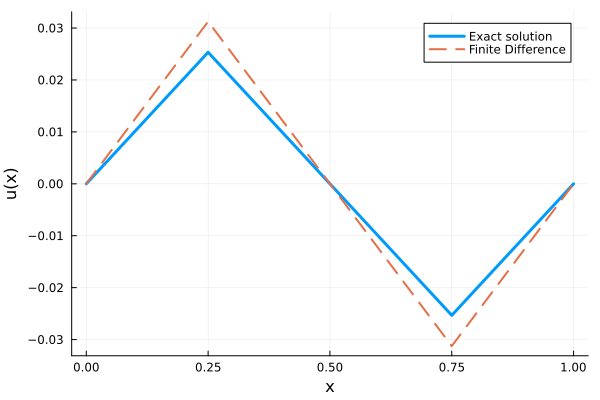

In [23]:
using LinearAlgebra
using Plots

# -----------------------------
# Problem setting
# -----------------------------

dt = 0.25
T = 1.0
x = 0:dt:T


xi = x[2:end-1]
n = length(xi)

# -----------------------------
# Construct finite difference matrix
# u'' =  - sin(2πx)
# -----------------------------
A = zeros(n, n)

for i in 1:n
    A[i,i] = - 2.0
    if i > 1
        A[i,i-1] =  1.0
    end
    if i < n
        A[i,i+1] = 1.0
    end
end

A ./= (dt)^2

# Right-hand side
f =  - sin.(2π .* xi)

# Solve linear system
u_interior = A \ f

# Include boundary values
u_num = vcat(0.0, u_interior, 0.0)

# -----------------------------
# Exact solution
# -----------------------------
u_exact_vec = (1/(2π)^2) .* sin.(2π .* x)

# -----------------------------
# Error
# -----------------------------
max_error = maximum(abs.(u_num .- u_exact_vec))
l2_error = sqrt(sum((u_num .- u_exact_vec).^2) * (dt))

println("Maximum error = ", max_error)
println("L2 error       = ", l2_error)

# -----------------------------
# Plot
# -----------------------------
plot(x, u_exact_vec,
    lw=3,
    label="Exact solution",
    xlabel="x",
    ylabel="u(x)")

plot!(x, u_num,
    linestyle=:dash,
    lw=2,
    label="Finite Difference")

In [24]:




X_train = collect(0:dt:1)
y_train = -sin.(2π .* X_train)



println("X_train:", X_train)
println("y_train:", y_train)

println(y_train.size)

 
#

X_train:[0.0, 0.25, 0.5, 0.75, 1.0]
y_train:[-0.0, -1.0, -1.2246467991473532e-16, 1.0, 2.4492935982947064e-16]
(5,)


In [25]:
#ℓ = best_ℓ
ℓ = 2.0
σf = 10.0
σn = 0.2

# -------------------------
# Test Points
# -------------------------
#X_test = collect(range(-5, 5, length=300))

X_test = collect(range(0, 1, length=300))
# -------------------------
# Covariance Matrices
# -------------------------



function laplacian_matrix(n, dt)

    # n = number of grid points (including boundary)
    D = zeros(n-2, n)

    #for i in 1:n-2
    #    D[i,i+1] = 1
    #end

    for i in 1:n-2
        D[i,i]   = 1
        D[i,i+1] = - 2
        D[i,i+2] = 1
    end

    return D ./ dt^2
end




function observation_matrix(n, dt)

    D = laplacian_matrix(n, dt)

    H = zeros(n, n)

    # u(0)
    H[1,1] = 1.0

    # Lu (internal)
    H[2:n-1, :] .= D

    # u(1)
    H[end,end] = 1.0

    return H
end

H = observation_matrix(length(X_train), dt)

println("H:", H)
println("H.size:", H.size)



#K =
#    kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf) +
#    σn^2 * I

K =
    H * kernel_matrix(X_train, X_train;
                  ℓ=ℓ, σf=σf) * H' +
#    σn^2 * I
     (0.0001) * I

#K =
#    kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf)  +
#    σn^2 * I

println("K.size:", K.size)

Ks =
    kernel_matrix(X_train, X_test;
                  ℓ=ℓ, σf=σf)

println("Ks.size:", Ks.size)

Ks = H * Ks

Kss =
    kernel_matrix(X_test, X_test;
                  ℓ=ℓ, σf=σf)

println("Kss.size:", Kss.size)

# -------------------------
# Posterior Mean
# -------------------------
μ =
    transpose(Ks) *
    (K \ y_train)

# -------------------------
# Posterior Covariance
# -------------------------
Σ =
    Kss -
    transpose(Ks) *
    (K \ Ks)

std =
    sqrt.(diag(Σ))

#

H:[1.0 0.0 0.0 0.0 0.0; 16.0 -32.0 16.0 0.0 0.0; 0.0 16.0 -32.0 16.0 0.0; 0.0 0.0 16.0 -32.0 16.0; 0.0 0.0 0.0 0.0 1.0]
H.size:(5, 5)
K.size:(5, 5)
Ks.size:(5, 300)
Kss.size:(300, 300)


300-element Vector{Float64}:
 0.009999946473417358
 0.009966598100619423
 0.009933391202218471
 0.009900324537692762
 0.009867397021740302
 0.00983460772198509
 0.009801955856603432
 0.009769440786051112
 0.009737061996566106
 0.009704819111865994
 ⋮
 0.009737061996566106
 0.00976944078459649
 0.009801955856603432
 0.00983460772198509
 0.00986739702102021
 0.009900324536257369
 0.009933391201503163
 0.009966598099906498
 0.009999946473417358

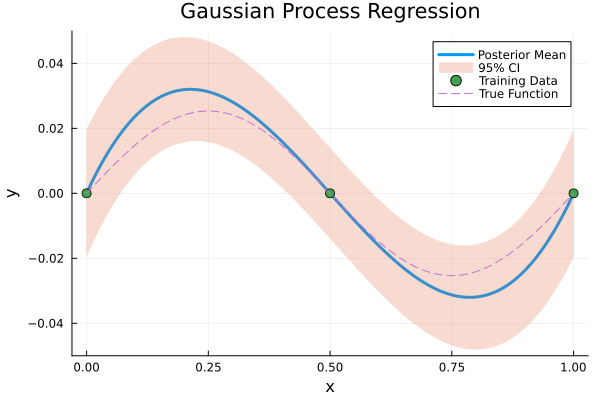

In [28]:
#-------------------------
# Visualization
# -------------------------
plot(
    X_test,
    μ,
    label="Posterior Mean",
    lw=3
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=μ .- 1.96 .* std,
    fillalpha=0.25,
    linealpha=0,
    label="95% CI"
)

scatter!(
    X_train,
    y_train,
    label="Training Data",
    ms=5
)

plot!(
    X_test,
    #sin.(X_test),
    (1/(2π)^2) * sin.(2π .* X_test),
    ylims = (-0.05, 0.05),
    ls=:dash,
    label="True Function"
)

xlabel!("x")
ylabel!("y")
title!("Gaussian Process Regression")